In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import nbimporter
from bike_sharing_data import get_bike_sharing

X_train, X_test, y_train, y_test = get_bike_sharing()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (13903, 12)
Testing data: (3476, 12)


In [3]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create KNN model
model = KNeighborsRegressor(
    n_neighbors=5,
    weights='uniform',
    metric='minkowski'
)

# Train
model.fit(X_train_scaled, y_train.values.ravel())

print("KNN Model training completed!")

KNN Model training completed!


In [4]:
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

In [5]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Evaluation on testing data
mae = mean_absolute_error(y_test, y_test_pred)

mse = mean_squared_error(y_test, y_test_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_test_pred)

print("KNN Model Evaluation on Test Data")
print("-----------------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

KNN Model Evaluation on Test Data
-----------------------------------
MAE : 70.53365937859608
MSE : 11116.763624856156
RMSE: 105.43606415670189
R2 Score: 0.6489303894796621


In [6]:
train_r2 = r2_score(y_train, y_train_pred)

# Compare training and testing performance
print("\nTraining R2:", train_r2)
print("Testing R2:", r2)


Training R2: 0.7750203242069403
Testing R2: 0.6489303894796621


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

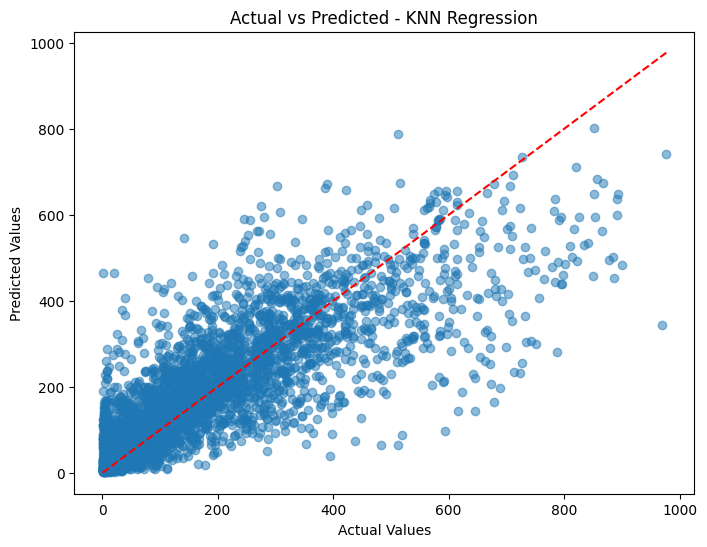

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - KNN Regression")

plt.show()

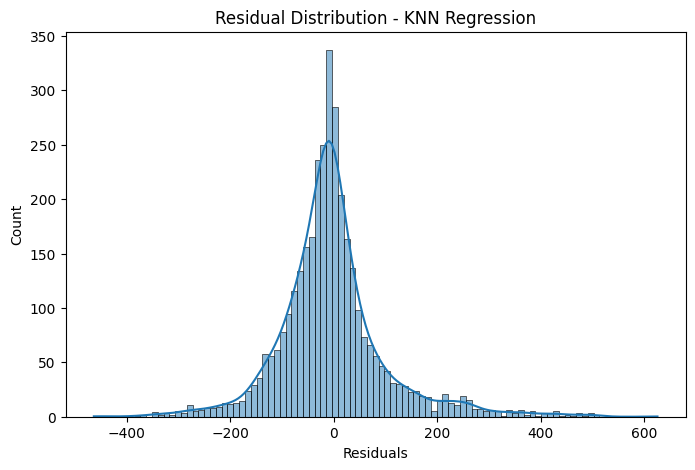

In [9]:
# Residual = Actual value - Predicted value

residuals = np.asarray(y_test).ravel() - y_test_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Residual Distribution - KNN Regression")

plt.show()

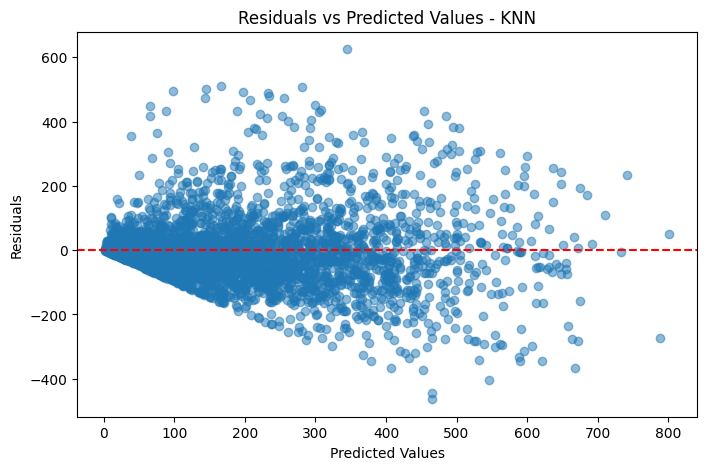

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test_pred, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values - KNN")

plt.show()

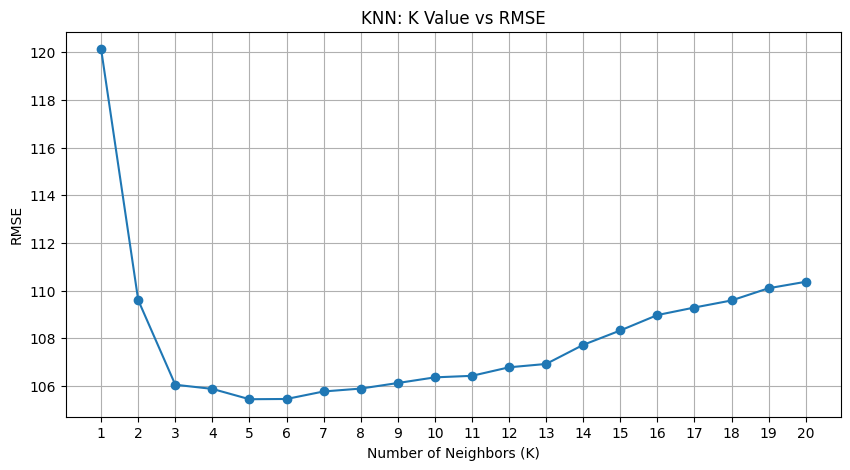

In [11]:
# Find the best K value

k_values = range(1, 21)

rmse_values = []

for k in k_values:

    knn = KNeighborsRegressor(n_neighbors=k)

    knn.fit(X_train_scaled, y_train.values.ravel())

    predictions = knn.predict(X_test_scaled)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    rmse_values.append(rmse)

# Plot K vs RMSE
plt.figure(figsize=(10, 5))

plt.plot(k_values, rmse_values, marker='o')

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("RMSE")
plt.title("KNN: K Value vs RMSE")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [12]:
# Train KNN with the best K value
best_k = list(k_values)[np.argmin(rmse_values)]

print("Best K value:", best_k)

model = KNeighborsRegressor(
    n_neighbors=best_k
)

model.fit(X_train_scaled, y_train.values.ravel())

y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

print("Optimized KNN Model training completed!")

Best K value: 5
Optimized KNN Model training completed!


In [13]:
knn_mae = mean_absolute_error(y_test, y_test_pred)
knn_mse = mean_squared_error(y_test, y_test_pred)
knn_rmse = np.sqrt(knn_mse)
knn_test_r2 = r2_score(y_test, y_test_pred)

print("KNN Model Evaluation")
print("-----------------------------------")
print("MAE :", knn_mae)
print("MSE :", knn_mse)
print("RMSE:", knn_rmse)
print("R2 Score:", knn_test_r2)

KNN Model Evaluation
-----------------------------------
MAE : 70.53365937859608
MSE : 11116.763624856156
RMSE: 105.43606415670189
R2 Score: 0.6489303894796621


In [14]:
knn_train_r2 = r2_score(y_train, y_train_pred)

# Compare training and testing performance
print("\nTraining R2:", knn_train_r2)
print("Testing R2:", knn_test_r2)


Training R2: 0.7750203242069403
Testing R2: 0.6489303894796621
